In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from my_week04 import *

In [20]:
import importlib
import my_week04

importlib.reload(my_week04)
from my_week04 import *

double_well = DoubleWell()

In [21]:
double_well = DoubleWell()

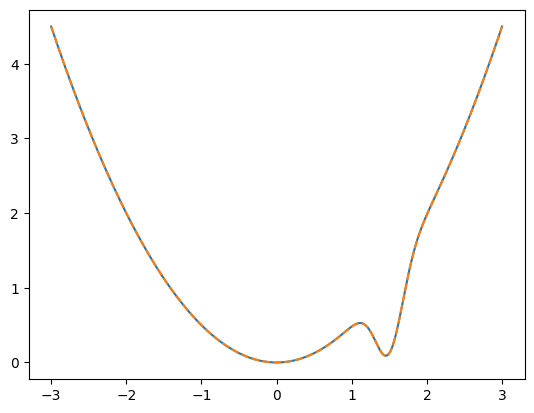

In [22]:
xs = np.linspace(-3,3,10000)
pot = double_well.potential_energy(xs)
force_integrated = double_well.integrate(xs)

plt.plot(xs, pot)
plt.plot(xs, force_integrated, ls="dashed")

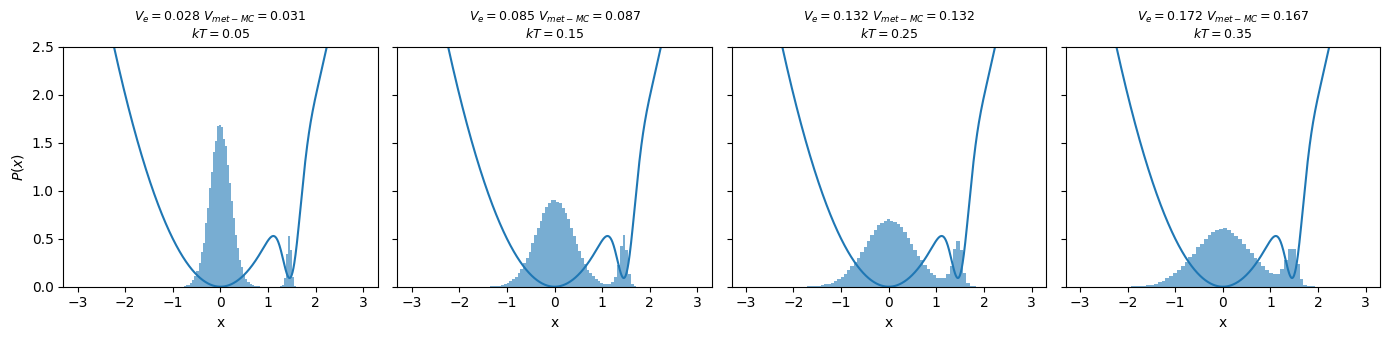

In [23]:
temperatures = [0.05, 0.15, 0.25, 0.35]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), sharey=True)
x_grid = np.linspace(-3, 3, 1000)

for ax, kT in zip(axes, temperatures):
    # 1. Direct energy calculation (returns single float)
    avg_E_dir = double_well.direct_integration(kT)
    samples, avg_E_mc = double_well.metropolis_mc(kT)
    
    # 2. Compute exact P(x) for plotting
    weights = np.exp(-double_well.potential_energy(x_grid) / kT)
    Z = quad(lambda x: np.exp(-double_well.potential_energy(x) / kT), -3, 3)[0]
    P_exact = weights / Z
    
    # 3. Plotting
    ax.hist(samples, bins=60, density=True, alpha=0.6, color='tab:blue')
    ax.plot(x_grid, double_well.potential_energy(x_grid), color='tab:blue', lw=1.5) # P_exact gives the envelope or whatever its called
    ax.set_title(f"$V_e={avg_E_dir:.3f}$ $V_{{met-MC}}={avg_E_mc:.3f}$\n$kT={kT}$", fontsize=9)
    ax.set_xlabel('x')
    ax.set_ylim(0,2.5)

axes[0].set_ylabel('$P(x)$')
#plt.set_xlim(-2,2)
plt.tight_layout()
plt.show()